# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [1]:
# Importar librerías necesarias
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cargar el conjunto de datos
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
# Visualizar las estadísticas iniciales
print("Estadísticas iniciales:")
data.describe()

Estadísticas iniciales:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
# Aplicar MinMaxScaler
minmax_scaler = MinMaxScaler()
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [5]:
# Aplicar StandardScaler
standard_scaler = StandardScaler()
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [6]:
# Mostrar estadísticas descriptivas de los datos originales
print("--- Estadísticas Originales ---")
print(data.describe())

# Mostrar estadísticas descriptivas de los datos con MinMaxScaler
print("\n--- Estadísticas MinMax ---")
print(data_minmax.describe())

--- Estadísticas Originales ---
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  

--- Estadísticas MinMax ---
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150

En los datos originales: Cada variable tiene un rango distinto de valores mínimos y máximos (por ejemplo, algunos varían entre $4.3$ y $7.9$, otros entre $2.0$ y $4.4$).En el escalado MinMax:El valor mínimo (min) de todas las columnas ahora es $0.0$.El valor máximo (max) de todas las columnas ahora es $1.0$.La forma de la distribución no cambia: Las relaciones relativas entre las observaciones se mantienen exactamente iguales.

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

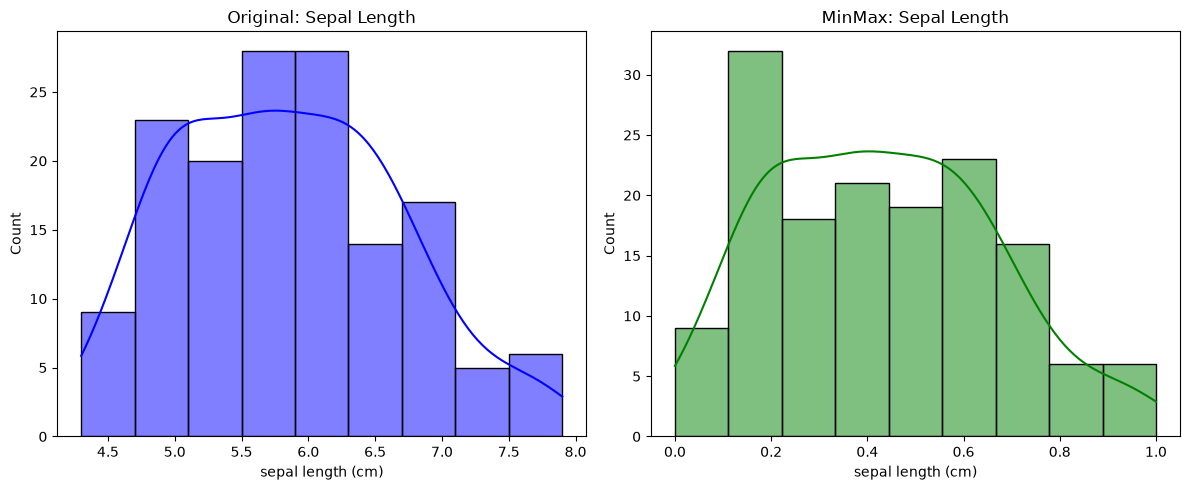

In [7]:
import seaborn as sns

plt.figure(figsize=(12, 5))

# Subplot 1: Distribución Original
plt.subplot(1, 2, 1)
sns.histplot(data['sepal length (cm)'], kde=True, color='blue')
plt.title('Original: Sepal Length')

# Subplot 2: Distribución MinMax
plt.subplot(1, 2, 2)
sns.histplot(data_minmax['sepal length (cm)'], kde=True, color='green')
plt.title('MinMax: Sepal Length')

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5)): Prepara un panel gráfico de $12$ unidades de ancho por $5$ de alto.plt.subplot(1, 2, 1): Divide la figura en $1$ fila y $2$ columnas, e indica que dibujaremos en la primera gráfica (izquierda).sns.histplot(..., kde=True): Genera el histograma junto con la curva de densidad para observar la forma de la distribución.plt.subplot(1, 2, 2): Cambia el foco para dibujar en la segunda gráfica (derecha) usando data_minmax['sepal length (cm)'].plt.tight_layout(): Ajusta los márgenes automáticamente para que las etiquetas no se empalmen.

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

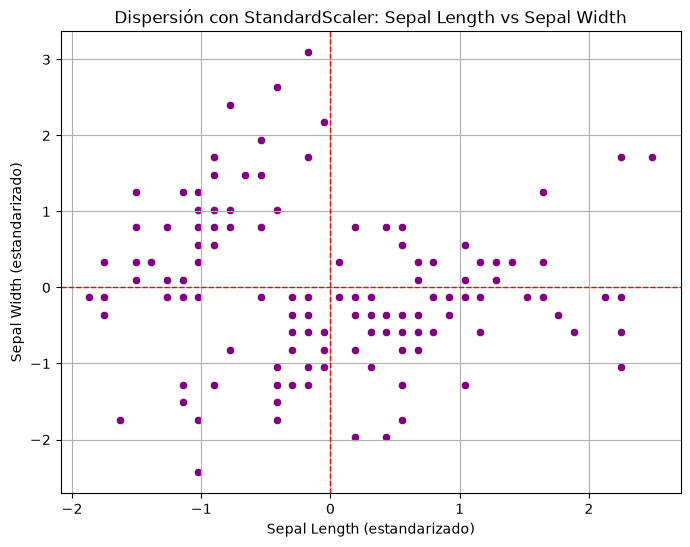

In [8]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x='sepal length (cm)', 
    y='sepal width (cm)', 
    data=data_standard, 
    color='purple'
)

plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.axvline(0, color='red', linestyle='--', linewidth=1)

plt.title('Dispersión con StandardScaler: Sepal Length vs Sepal Width')
plt.xlabel('Sepal Length (estandarizado)')
plt.ylabel('Sepal Width (estandarizado)')
plt.grid(True)
plt.show()

sns.scatterplot(x=..., y=..., data=data_standard): Crea una gráfica de puntos (dispersión) usando la tabla generada por StandardScaler.   plt.axhline(0, ...) y plt.axvline(0, ...): Dibuja dos líneas rojas punteadas que se cruzan en el origen $(0,0)$.¿Por qué en $(0,0)$? Porque StandardScaler centra los datos en la media $= 0$. Los puntos a la izquierda o abajo del eje rojo tienen valores inferiores al promedio, y los que están a la derecha o arriba son superiores al promedio. 

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

In [ ]:
# Respuesta teórica y recomendación:
"""
Para el conjunto de datos Iris, la técnica más adecuada es 'StandardScaler'.

Razones:
1. No presenta outliers extremos: El dataset Iris no contiene valores atípicos severos que puedan sesgar significativamente la media y desviación estándar.
2. Preserva distribuciones normales: 'StandardScaler' asume/preserva la forma aproximadamente gaussiana (normal) de las mediciones de las flores.
3. Compatibilidad con algoritmos de IA: La mayoría de los algoritmos de Machine Learning que utilizan funciones de costo o distancias (como SVM, KNN o Redes Neuronales) asumen implícitamente que los datos están centrados en cero con varianza unitaria.
"""